# TPI Análisis de Datos - Telco Customer Churn

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/andyargg/tpi-analisis-de-datos/blob/main/notebooks/TPI_Analisis_de_Datos.ipynb)

Introducción al Análisis de Datos - UTN Avellaneda - Div. 143
Profe: Zotti, Enzo Martín
Integrantes: Matias Asenjo, Damian Bello, Andres Arguindegui y J. Zubini

En este trabajo usamos el dataset Telco Customer Churn para ver por qué los clientes de una empresa
de telefonía/internet se dan de baja.

## 1. Los datos

### 1.1 Librerías y carga

Usamos pandas y numpy para trabajar con los datos, y matplotlib y seaborn para los gráficos.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)  # para que muestre todas las columnas

El csv lo leemos directo desde el repo de github, asi se puede correr en Colab sin subir nada.

In [3]:
url = "https://raw.githubusercontent.com/andyargg/tpi-analisis-de-datos/main/data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv"
df = pd.read_csv(url)

print("filas:", df.shape[0])
print("columnas:", df.shape[1])

filas: 7043
columnas: 21


### 1.2 Primer vistazo

In [4]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


### 1.3 Problema e hipótesis

La empresa está perdiendo clientes y queremos entender qué tienen en común los que se van, para que
puedan hacer algo para retenerlos antes de que cancelen.

La variable que nos interesa es **Churn** (Yes = se dio de baja, No = sigue siendo cliente). Veamos
cuántos hay de cada uno:

In [6]:
print(df["Churn"].value_counts())
print()
print(df["Churn"].value_counts(normalize=True) * 100)

Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


Se fue más o menos el 26% de los clientes, o sea 1 de cada 4. Hay muchos más "No" que "Yes", así que
cuando comparemos grupos vamos a usar porcentajes y no cantidades.

Hipótesis que queremos comprobar:

- H1: los que tienen contrato mes a mes se van más que los de 1 o 2 años (se pueden ir cuando quieren).
- H2: los clientes nuevos se van más que los que hace mucho que están.
- H3: los que pagan más por mes se van más.
- H4: los que pagan con cheque se van más que los que tienen débito automático.

### 1.4 Tipo de dataset y tipos de variables

El dataset es **estructurado** porque es una tabla: cada fila es un cliente y todas las filas tienen
las mismas columnas. No es semi-estructurado (tipo JSON) ni no estructurado (texto libre, imágenes, etc).

Ahora clasificamos cada variable (nominal, ordinal, discreta o continua) y lo comparamos con el tipo
que le puso pandas.

In [7]:
tipos = {
    "customerID": "identificador",
    "gender": "cualitativa nominal",
    "SeniorCitizen": "cualitativa nominal",
    "Partner": "cualitativa nominal",
    "Dependents": "cualitativa nominal",
    "tenure": "cuantitativa discreta",
    "PhoneService": "cualitativa nominal",
    "MultipleLines": "cualitativa nominal",
    "InternetService": "cualitativa nominal",
    "OnlineSecurity": "cualitativa nominal",
    "OnlineBackup": "cualitativa nominal",
    "DeviceProtection": "cualitativa nominal",
    "TechSupport": "cualitativa nominal",
    "StreamingTV": "cualitativa nominal",
    "StreamingMovies": "cualitativa nominal",
    "Contract": "cualitativa ordinal",
    "PaperlessBilling": "cualitativa nominal",
    "PaymentMethod": "cualitativa nominal",
    "MonthlyCharges": "cuantitativa continua",
    "TotalCharges": "cuantitativa continua",
    "Churn": "cualitativa nominal",
}

tabla = pd.DataFrame({
    "tipo": tipos,
    "dtype pandas": df.dtypes.astype(str),
    "valores distintos": df.nunique(),
})
tabla

,tipo,dtype pandas,valores distintos
customerID,identificador,object,7043
gender,cualitativa nominal,object,2
SeniorCitizen,cualitativa nominal,int64,2
Partner,cualitativa nominal,object,2
Dependents,cualitativa nominal,object,2
tenure,cuantitativa discreta,int64,73
PhoneService,cualitativa nominal,object,2
MultipleLines,cualitativa nominal,object,3
InternetService,cualitativa nominal,object,3
OnlineSecurity,cualitativa nominal,object,3


In [8]:
tabla["tipo"].value_counts()

,count
tipo,
cualitativa nominal,16
cuantitativa continua,2
identificador,1
cuantitativa discreta,1
cualitativa ordinal,1


Lo que no coincide:

- **TotalCharges** es plata (continua) pero pandas la leyó como texto (object). Seguro tiene algún valor
  raro que no es número, eso lo vemos en la limpieza.
- **SeniorCitizen** pandas la toma como número (int64) porque viene con 0 y 1, pero en realidad es
  sí/no, es categórica.
- **Contract** tiene orden (mes a mes < 1 año < 2 años) pero para pandas es texto normal.
- **customerID** es solo un código, no sirve para analizar, después la sacamos.

El resto está bien: las categóricas quedaron como texto y tenure y MonthlyCharges como números.

## 2. Limpieza

### 2.1 Valores nulos y TotalCharges

Primero vemos si hay nulos:

In [9]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


Pandas dice que no hay ninguno, pero TotalCharges venía como texto, así que buscamos celdas que
estén "vacías" pero con espacios:

In [10]:
vacios = df["TotalCharges"].str.strip() == ""
print("celdas vacías en TotalCharges:", vacios.sum())

df[vacios][["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

celdas vacías en TotalCharges: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


Son 11 y todos tienen **tenure = 0**, o sea que son clientes que se acaban de dar de alta y todavía
no les facturaron nada. Por eso los completamos con 0 en vez de borrarlos o poner el promedio (el
promedio no tendría sentido, en realidad no pagaron nada todavía).

Convertimos la columna a número. Con `errors="coerce"` lo que no se puede convertir queda como NaN
y después lo llenamos con 0.

In [11]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("nulos después de convertir:", df["TotalCharges"].isnull().sum())

df["TotalCharges"] = df["TotalCharges"].fillna(0)
print("nulos ahora:", df["TotalCharges"].isnull().sum())
print("tipo:", df["TotalCharges"].dtype)

nulos después de convertir: 11
nulos ahora: 0
tipo: float64


### 2.2 Duplicados

In [12]:
print("filas duplicadas:", df.duplicated().sum())
print("customerID repetidos:", df["customerID"].duplicated().sum())
print("filas iguales sin contar el ID:", df.drop(columns="customerID").duplicated().sum())

filas duplicadas: 0
customerID repetidos: 0
filas iguales sin contar el ID: 22


No hay filas duplicadas ni IDs repetidos. Hay 22 filas que son iguales si no miramos el ID, pero son
clientes distintos que justo tienen el mismo plan y los mismos datos, así que las dejamos.

### 2.3 Tipos de datos

SeniorCitizen viene con 0 y 1. La pasamos a "No"/"Yes" para que quede igual que las otras columnas
de sí/no (Partner, Dependents, etc) y no se confunda con un número.

In [13]:
df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})
df["SeniorCitizen"].value_counts()

,count
SeniorCitizen,
No,5901
Yes,1142


### 2.4 Columnas: eliminar, renombrar y crear

Sacamos customerID porque es solo un código y no sirve para el análisis. También renombramos
`gender` a `Gender` porque era la única columna en minúscula y así queda todo igual.

In [14]:
df = df.drop(columns=["customerID"])
df = df.rename(columns={"gender": "Gender"})
df.columns

Index(['Gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
       'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
       'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod',
       'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

Columnas nuevas:

- **ChurnNum**: Churn como número (1 = se fue, 0 = no). Sirve para sacar la tasa de baja con un
  promedio.
- **TotalEstimado**: cargo mensual x meses de antigüedad. Es lo que "debería" haber pagado si siempre
  hubiera pagado lo mismo.
- **CantServicios**: cuántos servicios extra tiene contratados (seguridad, backup, soporte, streaming, etc).
- **GrupoAntiguedad**: tenure agrupada en rangos de años, para comparar clientes nuevos y viejos.

In [15]:
df["ChurnNum"] = (df["Churn"] == "Yes").astype(int)

df["TotalEstimado"] = df["MonthlyCharges"] * df["tenure"]

servicios = ["OnlineSecurity", "OnlineBackup", "DeviceProtection",
             "TechSupport", "StreamingTV", "StreamingMovies"]
df["CantServicios"] = (df[servicios] == "Yes").sum(axis=1)

df["GrupoAntiguedad"] = pd.cut(df["tenure"], bins=[-1, 12, 24, 48, 72],
                               labels=["0-1 año", "1-2 años", "2-4 años", "4-6 años"])

df[["tenure", "MonthlyCharges", "TotalCharges", "TotalEstimado",
    "CantServicios", "GrupoAntiguedad", "Churn", "ChurnNum"]].head()

,tenure,MonthlyCharges,TotalCharges,TotalEstimado,CantServicios,GrupoAntiguedad,Churn,ChurnNum
0,1,29.85,29.85,29.85,1,0-1 año,No,0
1,34,56.95,1889.50,1936.30,2,2-4 años,No,0
2,2,53.85,108.15,107.70,2,0-1 año,Yes,1
3,45,42.30,1840.75,1903.50,3,2-4 años,No,0
4,2,70.70,151.65,141.40,0,0-1 año,Yes,1


### 2.5 Outliers

Buscamos valores atípicos en las variables numéricas con boxplots y con el método del rango
intercuartílico (IQR). Un valor es outlier si está por debajo de Q1 - 1.5*IQR o por arriba de
Q3 + 1.5*IQR.

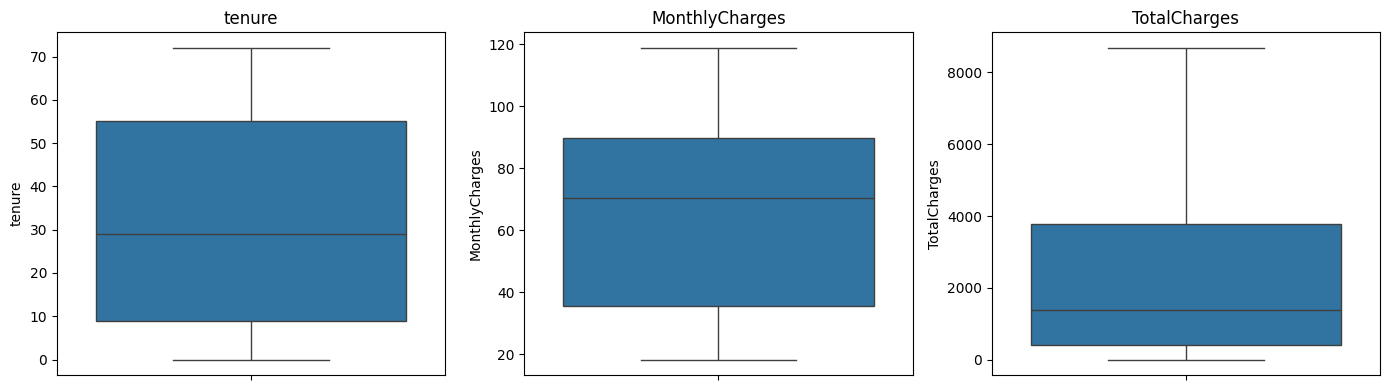

In [16]:
numericas = ["tenure", "MonthlyCharges", "TotalCharges"]

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, numericas):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [17]:
for col in numericas:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lim_inf = q1 - 1.5 * iqr
    lim_sup = q3 + 1.5 * iqr
    cant = ((df[col] < lim_inf) | (df[col] > lim_sup)).sum()
    print(f"{col}: Q1={q1:.2f}  Q3={q3:.2f}  límites=[{lim_inf:.2f}, {lim_sup:.2f}]  outliers={cant}")

tenure: Q1=9.00  Q3=55.00  límites=[-60.00, 124.00]  outliers=0
MonthlyCharges: Q1=35.50  Q3=89.85  límites=[-46.02, 171.38]  outliers=0
TotalCharges: Q1=398.55  Q3=3786.60  límites=[-4683.52, 8868.67]  outliers=0


No hay outliers en ninguna de las tres. TotalCharges tiene valores bastante altos (llega a más de
8000) pero no pasan el límite, y tiene sentido porque son clientes que hace muchos años que están.
Como son datos reales y no errores, no sacamos nada.

### 2.6 Guardar los datos limpios

In [18]:
import os

os.makedirs("data/processed", exist_ok=True)
df.to_csv("data/processed/telco_limpio.csv", index=False)

print("guardado:", df.shape)
df.info()

guardado: (7043, 24)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 24 columns):
 #   Column            Non-Null Count  Dtype   
---  ------            --------------  -----   
 0   Gender            7043 non-null   object  
 1   SeniorCitizen     7043 non-null   object  
 2   Partner           7043 non-null   object  
 3   Dependents        7043 non-null   object  
 4   tenure            7043 non-null   int64   
 5   PhoneService      7043 non-null   object  
 6   MultipleLines     7043 non-null   object  
 7   InternetService   7043 non-null   object  
 8   OnlineSecurity    7043 non-null   object  
 9   OnlineBackup      7043 non-null   object  
 10  DeviceProtection  7043 non-null   object  
 11  TechSupport       7043 non-null   object  
 12  StreamingTV       7043 non-null   object  
 13  StreamingMovies   7043 non-null   object  
 14  Contract          7043 non-null   object  
 15  PaperlessBilling  7043 non-null   object  
 16  Pay

Quedaron 7043 filas y 24 columnas (sacamos customerID y agregamos 4). Ya no hay nulos y TotalCharges
es numérica.

## 3. Variables numéricas

### 3.1 Medidas de tendencia central y dispersión


In [19]:
num = ["tenure", "MonthlyCharges", "TotalCharges"]
df[num].describe()


,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000
mean,32.371149,64.761692,2279.734304
std,24.559481,30.090047,2266.794470
min,0.000000,18.250000,0.000000
25%,9.000000,35.500000,398.550000
50%,29.000000,70.350000,1394.550000
75%,55.000000,89.850000,3786.600000
max,72.000000,118.750000,8684.800000


Con estos datos se puede interpretar lo siguiente sobre cada campo:
* **Antiguedad de cliente** (tenure)
  * **Promedio y dispersión**: En promedio podemos ver que los clientes llevan 32 meses en la empresa, pero una dispersión tan alta (casi 25) indica perfiles muy distintos entre clientes nuevos y antiguos
  * **Mín y Max**: En el mínimo y máximo podemos ver que existen clientes recién incorporados, por eso su tenure es de 0 meses, y clientes con hasta 72 meses de antiguedad
  * **Cuartiles**:
    * **Q1**: El 25% más nuevo de los clientes lleva 9 meses o menos como cliente
    * **Q2 (mediana)**: La mitad de los clientes tiene 29 meses o menos de antiguedad y la otra mitad tiene más
    * **Q3**: El 75% de los clientes tiene 55 meses o menos en la empresa
* **Cargo mensual** (MonthlyCarges)
  * **Promedio y dispersión**: En promedio el gasto mensual es de unos 64.76 dolares, con una variación de 30 dolares debido a los diferentes servicios contratados.
  * **Mín y Max**: La factura mensual más económica es de 18.25 dolares y la más alta llega a 118.75
  * **Cuartiles**:
    * **Q1**: El 25% de los clientes paga 35.50 dolares o menos por mes.
    * **Q2 (mediana)**: La mitad de los clientes paga menos de 70.35 dolares por mes y la otra mitad paga más. (Nota: al ser mayor que el promedio, indica que hay un grupo mucho más grande de gente que paga una mensualidad más baja)
    * **Q3**: El 75% de los clientes paga 89.85 o menos por mes
* **Cargo total acumulado** (TotalCharges)
  * **Promedio y dispersión**: En promedio el ingreso acumulado por cliente es de unos 2279.73 dolares y la dispersión es casi igual de grande (2266.79), esto se debe a la combinación de distintas antiguedades y tarifas
  * **Mín y Max**: El mínimo es 0 correspondiente a aquellos nuevos clientes que todavía no pagaron su primer factura y el máximo corresponde a los clientes con muchos años de antiguedad
  * **Cuartiles**:
    * **Q1**: El 25% de los clientes acumuló un gasto de 398.55 dolares o menos
    * **Q2 (mediana)**: La mitad de los clientes gastó en total 1394.55 dolares o menos
    * **Q3**: El 75% de los clientes acumuló 3786.60 dolares o menos



### 3.2 Comparación entre clientes que se fueron y los que se quedaron

In [20]:
df.groupby("Churn")[num].agg(["mean", "median", "std"])


tenure                   MonthlyCharges                     \
            mean median        std           mean  median        std   
Churn                                                                  
No     37.569965   38.0  24.113777      61.265124  64.425  31.092648   
Yes    17.979133   10.0  19.531123      74.441332  79.650  24.666053   

      TotalCharges                         
              mean    median          std  
Churn                                      
No     2549.911442  1679.525  2329.954215  
Yes    1531.796094   703.550  1890.822994

**Antiguedad del cliente**: En promedio podemos ver que los clientes que se quedaron tienen más de 3 años en la empresa, mientras que por otro lado los clientes que abandonaron tienen un promedio de casi 18 meses y una mediana de 10 meses, es decir que la mitad de los que se fueron lo hicieron antes de los 10 meses. Esto apunta directamente hacia nuestra segunda hipótesis.

**Cargo mensual**: En promedio los clientes que se quedaron pagan 61.27 dolares al mes con una dispersión alta (31.09) indicando que existen clientes en planes económicos como costosos. Por otro lado, los clientes que se fueron pagan en promedio 74.44 dolares al mes con una dispersión menor (24.67). Esto apunta hacia nuestra tercera hipótesis ya que los que se dan de baja pagan una factura con un valor mucho más alto.

**Cargo total acumulado**: Por supuesto existe una diferencia enorme entre el promedio de los que se quedaron y los que se fueron ya que estos últimos no aportaron el suficiente tiempo en la empresa como para acumular un aporte mayor (en promedio 2549.90 dolares los que se quedaron contra 1531.80 los que se fueron)

### 3.3 Histogramas con KDE

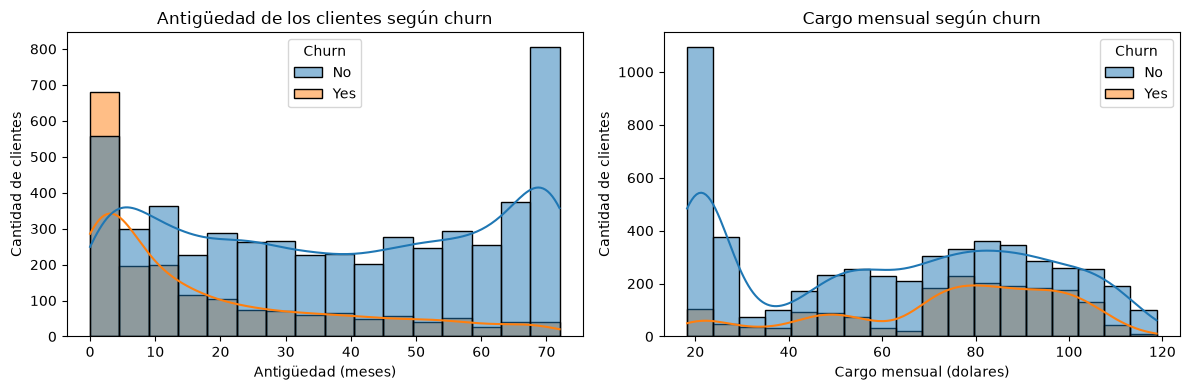

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=df, x="tenure", hue="Churn", kde=True, ax=axes[0])
sns.histplot(data=df, x="MonthlyCharges", hue="Churn", kde=True, ax=axes[1])

axes[0].set_title("Antigüedad de los clientes según churn")
axes[0].set_xlabel("Antigüedad (meses)")
axes[0].set_ylabel("Cantidad de clientes")
axes[1].set_title("Cargo mensual según churn")
axes[1].set_xlabel("Cargo mensual (dolares)")
axes[1].set_ylabel("Cantidad de clientes")
plt.tight_layout()
plt.show()

**Antiguedad del cliente**: Efectivamente podemos comprobar en el histograma que la baja de clientes se presenta en la etapa más temprana del tenure (entre 0 y 10 meses). A partir de ahí podemos ver como la línea naranja disminuye de forma constante indicando una mayor tasa de retención de clientes.

**Cargos mensuales**: En este gráfico podemos ver que la línea de churn arranca muy bajo indicando una menor cantidad de bajas de clientes pero esta va aumentando a medida que el valor mensual se va incrementando (entre los 70 y 100 dolares)

### 3.4 Correlación de Pearson y heatmap

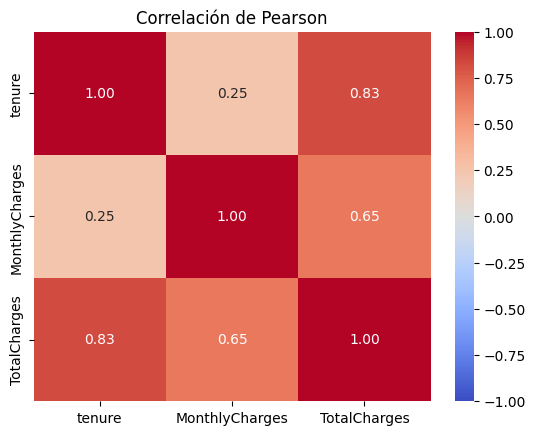

In [22]:
corr = df[num].corr(method="pearson")
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlación de Pearson")
plt.show()

Con este gráfico podemos determinar lo siguiente:

* Existe una correlación positiva muy fuerte entre el tiempo de antiguedad (tenure) y el cargo total acumulado (total charges), con un valor de 0.83, y esto es lógico, ya que a mayor tiempo como cliente, mayor es el monto total que acumuló en sus pagos.

* Se puede observar que hay una correlación positiva moderada entre los cargos mensuales (monthlyCharge) y el total acumulado (totalCharges), de 0.65, ya que los que tienden a pagar facturas más caras tienden a acumular un monto total mayor con el paso del tiempo.

* Existe una correlación positiva débil entre el tiempo de antiguedad (tenure) y los cargos mensuales (monthlyCharges), de solo 0.25, indicando que casi no existe una relación porque tenemos clientes nuevos con planes caros y clientes antiguos con planes baratos.

* Igual hay que tener en cuenta que correlación no significa causa: que dos variables se muevan juntas no quiere decir que una provoque la otra.

## 4. Variables categóricas



In [23]:
cat_cols = [
    col
    for col in [
        "gender",
        "SeniorCitizen",
        "Partner",
        "Dependents",
        "PhoneService",
        "MultipleLines",
        "InternetService",
        "OnlineSecurity",
        "OnlineBackup",
        "DeviceProtection",
        "TechSupport",
        "StreamingTV",
        "StreamingMovies",
        "Contract",
        "PaperlessBilling",
        "PaymentMethod",
        "GrupoAntiguedad",
    ]
    if col in df.columns
]

for col in cat_cols:
  freq = df[col].value_counts(dropna=False)
  pct = (df[col].value_counts(normalize=True, dropna=False) * 100).round(2)
  resumen = pd.DataFrame({"Cantidad": freq, "Porcentaje (%)": pct})
  print(f"\n=== {col} ===")
  display(resumen)


=== SeniorCitizen ===


,Cantidad,Porcentaje (%)
SeniorCitizen,,
No,5901,83.79
Yes,1142,16.21



=== Partner ===


,Cantidad,Porcentaje (%)
Partner,,
No,3641,51.7
Yes,3402,48.3



=== Dependents ===


,Cantidad,Porcentaje (%)
Dependents,,
No,4933,70.04
Yes,2110,29.96


... (22 outputs left out)


=== PaymentMethod ===


,Cantidad,Porcentaje (%)
PaymentMethod,,
Electronic check,2365,33.58
Mailed check,1612,22.89
Bank transfer (automatic),1544,21.92
Credit card (automatic),1522,21.61



=== GrupoAntiguedad ===


,Cantidad,Porcentaje (%)
GrupoAntiguedad,,
4-6 años,2239,31.79
0-1 año,2186,31.04
2-4 años,1594,22.63
1-2 años,1024,14.54


In [24]:
if "ChurnNum" not in df.columns:
  df["ChurnNum"] = (df["Churn"] == "Yes").astype(int)
tablas = []

for col in cat_cols:
  res = (
      df.groupby(col, observed=False)
      .agg(
          Total_Clientes=("ChurnNum", "count"),
          Bajas=("ChurnNum", "sum"),
          Tasa_Churn_pct=("ChurnNum", lambda s: round(s.mean() * 100, 2)),
      )
      .reset_index()
  )
  res.insert(0, "Variable", col)
  res = res.rename(columns={col: "Categoria"})
  tablas.append(res)

df_churn_cat = pd.concat(tablas, ignore_index=True)

display(
    df_churn_cat[df_churn_cat["Total_Clientes"] >= 50].sort_values(
        by="Tasa_Churn_pct", ascending=False
    )
)

,Variable,Categoria,Total_Clientes,Bajas,Tasa_Churn_pct
41,GrupoAntiguedad,0-1 año,2186,1037,47.44
39,PaymentMethod,Electronic check,2365,1071,45.29
32,Contract,Month-to-month,3875,1655,42.71
12,InternetService,Fiber optic,3096,1297,41.89
14,OnlineSecurity,No,3498,1461,41.77
1,SeniorCitizen,Yes,1142,476,41.68
23,TechSupport,No,3473,1446,41.64
17,OnlineBackup,No,3088,1233,39.93
20,DeviceProtection,No,3095,1211,39.13
29,StreamingMovies,No,2785,938,33.68


/tmp/ipykernel_780/2536143318.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_780/2536143318.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_780/2536143318.py:33: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


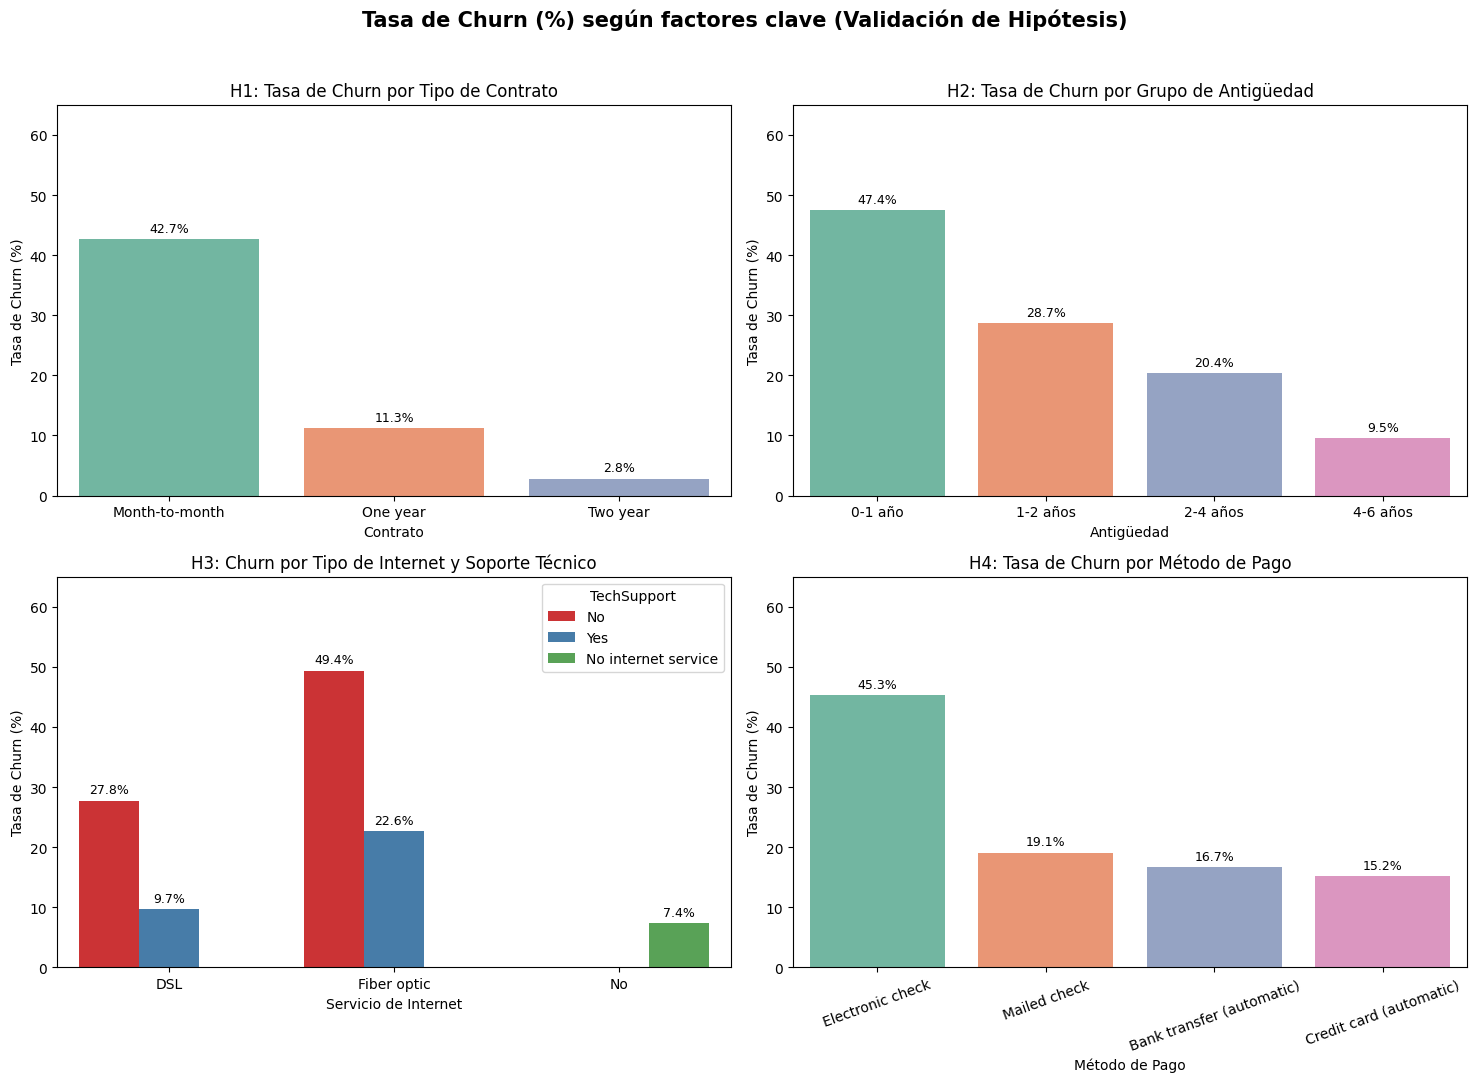

In [25]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11))
fig.suptitle("Tasa de Churn (%) según factores clave (Validación de Hipótesis)", fontsize=15, fontweight="bold")

# H1: Tipo de Contrato
sns.barplot(
    data=df, x="Contract", y="ChurnNum", ax=axes[0, 0],
    estimator=lambda x: x.mean() * 100, errorbar=None, palette="Set2",
    order=["Month-to-month", "One year", "Two year"]
)
axes[0, 0].set_title("H1: Tasa de Churn por Tipo de Contrato")
axes[0, 0].set_ylabel("Tasa de Churn (%)")
axes[0, 0].set_xlabel("Contrato")

# H2: Antigüedad (Tenure en grupos)
sns.barplot(
    data=df, x="GrupoAntiguedad", y="ChurnNum", ax=axes[0, 1],
    estimator=lambda x: x.mean() * 100, errorbar=None, palette="Set2"
)
axes[0, 1].set_title("H2: Tasa de Churn por Grupo de Antigüedad")
axes[0, 1].set_ylabel("Tasa de Churn (%)")
axes[0, 1].set_xlabel("Antigüedad")

# H3: Servicio de Internet y Soporte Técnico
sns.barplot(
    data=df, x="InternetService", y="ChurnNum", hue="TechSupport", ax=axes[1, 0],
    estimator=lambda x: x.mean() * 100, errorbar=None, palette="Set1"
)
axes[1, 0].set_title("H3: Churn por Tipo de Internet y Soporte Técnico")
axes[1, 0].set_ylabel("Tasa de Churn (%)")
axes[1, 0].set_xlabel("Servicio de Internet")

# H4: Método de Pago
sns.barplot(
    data=df, x="PaymentMethod", y="ChurnNum", ax=axes[1, 1],
    estimator=lambda x: x.mean() * 100, errorbar=None, palette="Set2"
)
axes[1, 1].set_title("H4: Tasa de Churn por Método de Pago")
axes[1, 1].set_ylabel("Tasa de Churn (%)")
axes[1, 1].set_xlabel("Método de Pago")
axes[1, 1].tick_params(axis="x", rotation=20)

# Agregar etiquetas de porcentaje encima de cada barra
for ax in axes.flat:
    for container in ax.containers:
        ax.bar_label(container, fmt="%.1f%%", padding=3, fontsize=9)
    ax.set_ylim(0, 65)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

### Observaciones sobre Variables Categóricas y Tasas de Churn

* **Tipo de contrato (`Contract` - H1):** Es el predictor categórico más fuerte de abandono. Los clientes con contrato **mes a mes (`Month-to-month`)** presentan una tasa de Churn del **42.7%**, frente al **11.3%** en contratos de 1 año y apenas **2.8%** en contratos de 2 años.
* **Antigüedad (`GrupoAntiguedad` - H2):** El abandono se concentra fuertemente en los primeros meses: los clientes nuevos (`0-12 meses`) tienen una tasa de Churn cercana al **47.4%**, que cae drásticamente a medida que superan el primer año.
* **Servicios y Soporte Técnico (`InternetService` y `TechSupport` - H3):** Los clientes con **Fibra Óptica (`Fiber optic`)** tienen una tasa de fuga muy elevada (**41.9%**), especialmente cuando **no cuentan con Soporte Técnico (`TechSupport = No`)** o Seguridad Online. En cambio, quienes tienen soporte técnico activo reducen su tasa de abandono a menos de la mitad.
* **Método de pago (`PaymentMethod` - H4):** Quienes pagan mediante **cheque electrónico (`Electronic check`)** muestran una tasa de abandono del **45.3%**, más del doble que los métodos automáticos (transferencia bancaria o tarjeta de crédito automática, que rondan el **15% - 17%**).
* **Variables demográficas (`Gender`, `Partner`, `Dependents`):** El género no tiene impacto alguno (~26% en ambos sexos). En cambio, los clientes sin pareja ni personas a cargo (`No`) y los adultos mayores (`SeniorCitizen = Sí`, **41.7%**) presentan mayor propensión a darse de baja.

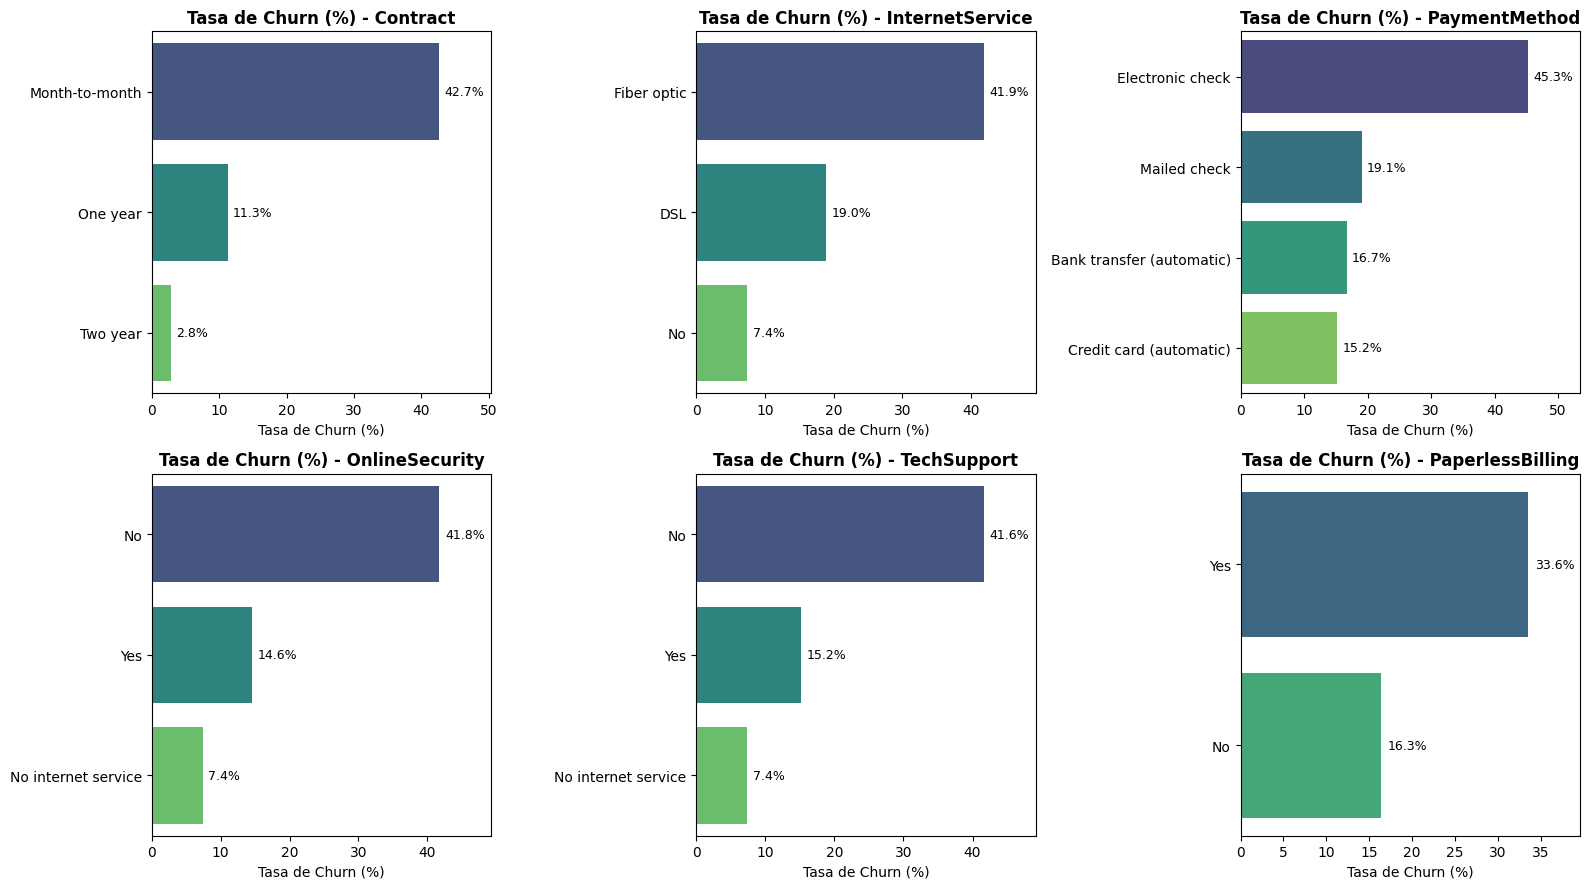

In [26]:
vars_grafico = [
    col
    for col in [
        "Contract",
        "InternetService",
        "PaymentMethod",
        "OnlineSecurity",
        "TechSupport",
        "PaperlessBilling",
    ]
    if col in df.columns
]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, col in enumerate(vars_grafico):
  tasa = (
      df.groupby(col, observed=False)["ChurnNum"]
      .mean()
      .mul(100)
      .sort_values(ascending=False)
  )
  sns.barplot(
      x=tasa.values,
      y=tasa.index,
      hue=tasa.index,
      palette="viridis",
      legend=False,
      ax=axes[i],
  )
  axes[i].set_title(f"Tasa de Churn (%) - {col}", fontweight="bold")
  axes[i].set_xlabel("Tasa de Churn (%)")
  axes[i].set_ylabel("")
  axes[i].set_xlim(0, max(tasa.values.max() * 1.18, 10))

  for bar in axes[i].patches:
    w = bar.get_width()
    axes[i].text(
        w + 0.8,
        bar.get_y() + bar.get_height() / 2,
        f"{w:.1f}%",
        va="center",
        ha="left",
        fontsize=9,
    )

for j in range(len(vars_grafico), len(axes)):
  axes[j].set_visible(False)

plt.tight_layout()
plt.show()

### Observaciones principales
* **Contrato (`Contract`):** los clientes con contrato mensual (*Month-to-month*) presentan una tasa de baja mucho mayor que quienes tienen contratos de uno o dos años.
* **Servicios y soporte (`InternetService`, `OnlineSecurity`, `TechSupport`):** la ausencia de servicios adicionales como seguridad o soporte técnico suele asociarse a una mayor proporción de bajas.
* **Facturación y pago (`PaperlessBilling`, `PaymentMethod`):** conviene comparar si los medios de pago no automáticos o la facturación digital acompañan una mayor rotación.

## 5. Segmentación y conclusiones

Clientes  Bajas  Tasa_Churn_Pct  \
Contract       InternetService                                    
Month-to-month Fiber optic          2128   1162            54.6   
               DSL                  1223    394            32.2   
One year       Fiber optic           539    104            19.3   
Month-to-month No                    524     99            18.9   
One year       DSL                   570     53             9.3   
Two year       Fiber optic           429     31             7.2   
One year       No                    364      9             2.5   
Two year       DSL                   628     12             1.9   
               No                    638      5             0.8   

                                Cargo_Mensual_Prom  
Contract       InternetService                      
Month-to-month Fiber optic                    87.0  
               DSL                            50.2  
One year       Fiber optic                    98.8  
Month-to-month No                             20.4  
One year       DSL                            61.4  
Two year       Fiber optic                   104.6  
One year       No                             20.8  
Two year       DSL                            70.5  
               No                             21.8

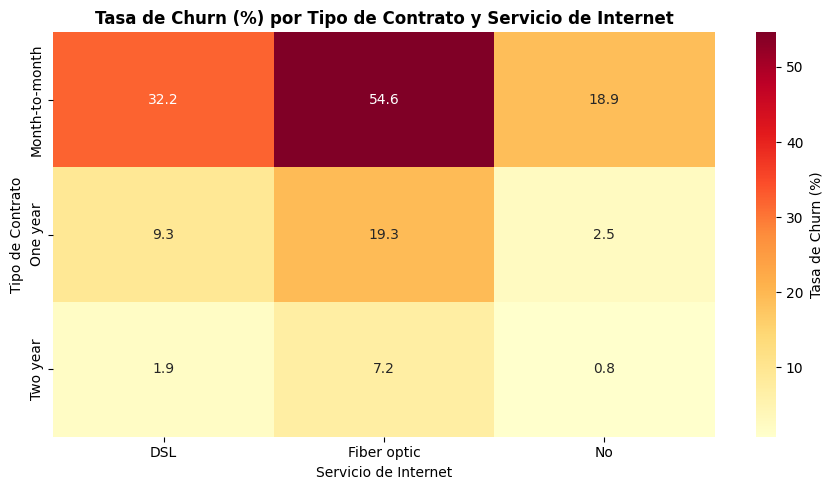

In [27]:
if "ChurnNum" not in df.columns:
  df["ChurnNum"] = (df["Churn"] == "Yes").astype(int)

segmentos = (
    df.groupby(["Contract", "InternetService"], observed=False)
    .agg(
        Clientes=("ChurnNum", "count"),
        Bajas=("ChurnNum", "sum"),
        Tasa_Churn_Pct=("ChurnNum", lambda s: round(s.mean() * 100, 1)),
        Cargo_Mensual_Prom=("MonthlyCharges", lambda s: round(s.mean(), 1)),
    )
    .sort_values(by="Tasa_Churn_Pct", ascending=False)
)

display(segmentos)

pivot_churn = df.pivot_table(
    index="Contract",
    columns="InternetService",
    values="ChurnNum",
    aggfunc=lambda s: s.mean() * 100,
)
orden_contrato = [
    c for c in ["Month-to-month", "One year", "Two year"] if c in pivot_churn.index
]
pivot_churn = pivot_churn.loc[orden_contrato]

fig, ax = plt.subplots(figsize=(9, 5))
sns.heatmap(
    pivot_churn,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    cbar_kws={"label": "Tasa de Churn (%)"},
    ax=ax,
)
ax.set_title(
    "Tasa de Churn (%) por Tipo de Contrato y Servicio de Internet",
    fontweight="bold",
)
ax.set_xlabel("Servicio de Internet")
ax.set_ylabel("Tipo de Contrato")
plt.tight_layout()
plt.show()

### 5.1 Segmentación de clientes según riesgo de baja

Sobre una base de **7.043 clientes**, la tasa general de abandono (*Churn*) es del **26.5%** (**1.869 bajas**). A partir de los patrones observados se distinguen tres perfiles principales:

* **Riesgo alto:** clientes con contrato **mes a mes (`Month-to-month`)**, **poca antigüedad (`0-1 año`, 47.4% de baja)**, pago con **cheque electrónico (`Electronic check`, 45.3%)** o **fibra óptica (`Fiber optic`, 41.9%)** sin soporte técnico ni servicios adicionales. En particular, quienes combinan contrato mes a mes y fibra óptica alcanzan un **54.6%** de tasa de baja.
* **Riesgo medio:** clientes con antigüedad intermedia (**1 a 4 años**), planes con **DSL** o contratos de **1 año (11.3% de baja)**, donde el abandono baja de forma notoria frente al segmento anterior.
* **Riesgo bajo:** clientes con **contratos de 2 años (2.8% de baja)**, mayor antigüedad (**4-6 años**, **9.5% de baja**), métodos de pago automáticos (**~15%–17%**) y mayor cantidad de servicios contratados.

### 5.2 Validación de hipótesis

* **H1 (Contrato mes a mes vs. 1 o 2 años):** **Confirmada.** Los contratos `Month-to-month` registran **42.7%** de baja, frente a **11.3%** en `One year` y **2.8%** en `Two year`.
* **H2 (Clientes nuevos vs. antiguos):** **Confirmada.** Los clientes de `0-1 año` presentan **47.4%** de tasa de *Churn*, mientras que en `4-6 años` cae a **9.5%** (y la mediana de antigüedad de quienes se van es de **10 meses** frente a **38 meses** en quienes permanecen).
* **H3 (Mayor cargo mensual = mayor baja):** **Confirmada.** Quienes se dan de baja tienen un cargo mensual promedio mayor (**$74.44**) que quienes continúan (**$61.27**), asociado en buena medida a planes de fibra óptica y servicios extra.
* **H4 (Cheque vs. débito automático):** **Confirmada.** El pago con `Electronic check` alcanza **45.3%** de baja, muy por encima de la transferencia bancaria automática (**16.7%**) y la tarjeta de crédito automática (**15.2%**).

### 5.3 Conclusiones y posibles acciones

El abandono se concentra en clientes recientes, con contratos sin permanencia y cargos mensuales más altos (especialmente en fibra óptica sin soporte). Como líneas de acción para el negocio conviene:
1. Reforzar la retención y el acompañamiento en los **primeros 12 meses** (onboarding, seguimiento y beneficios iniciales).
2. Incentivar el paso de contratos **mes a mes a planes anuales** mediante descuentos o beneficios progresivos.
3. Promover el **débito automático** frente al cheque electrónico y revisar la experiencia/soporte en clientes de **fibra óptica** sin `TechSupport`.